# Early Warning System for Food Price Inflation in Botswana
### A Two-Stage Regression and Classification Approach Using Regional and Global Economic Indicators

**BIDA Research and Innovation Project**

This notebook covers the full CRISP-DM pipeline: data merging, cleaning, feature engineering, EDA, regression modelling (Stage 1: predicting the inflation rate), classification modelling (Stage 2: risk categorisation), and evaluation.

**Revision note.** This version corrects methodological issues found in earlier drafts and, in its latest review round, (a) drops the food CPI level from the main feature set after validation preferred the version without it, (b) repeats the neighbouring-country tests at 3 months ahead (Sections 13–14), and (c) adds rolling forecast origins with Diebold–Mariano tests (Section 15). The original corrections were: (1) the forecast horizon was effectively two months, not one, because the latest known month was never used as a feature; (2) no simple benchmark was reported, so R² could not be interpreted; (3) models were selected on the same test set used for the final scores. Every model below is now compared with naive benchmarks, at 1, 2 and 3 months ahead, with model selection done on a separate validation window.

## Section 1: Setup & Imports

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from xgboost import XGBRegressor, XGBClassifier
from sklearn.metrics import (
    mean_squared_error, mean_absolute_error, r2_score,
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, ConfusionMatrixDisplay
)

sns.set_style("whitegrid")
print("Libraries imported successfully")
from sklearn.metrics import classification_report

Libraries imported successfully


## Section 2: Load & Merge the Raw Datasets

We combine three separate sources into one aligned monthly table:
- `01_baltic_dry_index_daily.csv` — global shipping index (daily → resampled to monthly average)
- `02_brent_crude_monthly.csv` — global oil price (monthly)
- `05_human_capital_project.csv` — CPI and food price inflation for 5 countries (we filter to Botswana here; the four neighbours are used in Sections 13–14)

**Policy rate excluded.** `03_botswana_policy_rate.csv` is deliberately not loaded. The supplied series is inconsistent with the Bank of Botswana's published Bank Rate (see Section 3), and a verified replacement series could not be obtained, so the policy rate is **excluded** from all models in this notebook. No conclusion about the policy rate or monetary policy is drawn.

Note: `04_fao_botswana_prices.csv` is not used, since it duplicates the Botswana rows already present in file 05.

In [2]:
df5 = pd.read_csv("05_human_capital_project.csv")
df5["Date"] = pd.to_datetime(df5["Date"])

panel = df5.pivot_table(
    index=["Date", "REF_AREA_LABEL"], columns="INDICATOR_LABEL", values="Value"
).reset_index()
panel = panel.rename(columns={
    "REF_AREA_LABEL": "Country",
    "Consumer Prices, General Indices (2015 = 100)": "CPI_General",
    "Consumer Prices, Food Indices (2015 = 100)": "CPI_Food",
    "Food price inflation": "Food_Price_Inflation",
})

brent = pd.read_csv("02_brent_crude_monthly.csv")
brent["Date"] = pd.to_datetime(brent["Date"]).values.astype("datetime64[M]")
brent = brent.rename(columns={"Brent_USD_per_barrel": "Brent_Crude_USD"})
brent = brent.groupby("Date", as_index=False)["Brent_Crude_USD"].mean()

bdi = pd.read_csv("01_baltic_dry_index_daily.csv")
bdi["Date"] = pd.to_datetime(bdi["Date"])
bdi_monthly = (
    bdi.set_index("Date")["BDI_Close"].resample("MS").mean()
    .reset_index().rename(columns={"BDI_Close": "Baltic_Dry_Index_Avg"})
)


panel["Date"] = panel["Date"].values.astype("datetime64[M]")
panel = panel.merge(brent, on="Date", how="left")
panel = panel.merge(bdi_monthly, on="Date", how="left")

# Narrow to Botswana only (per project decision)
df = panel[panel["Country"] == "Botswana"].copy()
df = df.sort_values("Date").reset_index(drop=True)
df = df[["Date", "CPI_General", "CPI_Food", "Food_Price_Inflation",
         "Brent_Crude_USD", "Baltic_Dry_Index_Avg"]]

print("Merged Botswana-only dataset shape:", df.shape)
df.head()

Merged Botswana-only dataset shape: (288, 6)


,Date,CPI_General,CPI_Food,Food_Price_Inflation,Brent_Crude_USD,Baltic_Dry_Index_Avg
0,2000-01-01,31.748320,31.912372,NaN,25.51,1370.550000
1,2000-02-01,31.974914,32.163038,NaN,27.78,1392.952381
2,2000-03-01,32.277040,32.413704,NaN,27.49,1620.695652
3,2000-04-01,32.679873,32.612508,NaN,22.76,1666.588235
4,2000-05-01,32.881290,32.811312,NaN,27.74,1601.800000


## Section 3: Data Cleaning

The first 12 months (2000) have no valid year-on-year inflation figure, since there's no prior year to compare against — these rows are dropped.

**Policy rate excluded.** The supplied policy-rate file (`03_botswana_policy_rate.csv`) shows exactly 12% from 2004 to May 2022 and then 1.65%. This is inconsistent with the Bank of Botswana's published Bank Rate, which was 7.5% in 2014 and 3.75% from October 2020 (cut from 4.25%, per the Bank's October 2020 Monetary Policy Committee statement). The file cannot be reconciled with the published record, and a verified replacement series could not be obtained, so the policy rate is **excluded from all models**. This notebook therefore says nothing about the role of the policy rate or of monetary policy in food inflation.

In [3]:
df = df[df["Date"] >= "2001-01-01"].reset_index(drop=True)

print("Shape after dropping 2000:", df.shape)
print("\nMissing values per column:")
print(df.isnull().sum())

Shape after dropping 2000: (276, 6)

Missing values per column:
Date                    0
CPI_General             0
CPI_Food                0
Food_Price_Inflation    0
Brent_Crude_USD         0
Baltic_Dry_Index_Avg    0
dtype: int64


## Section 4: Feature Engineering — Lags and the Forecast Horizon

For a forecast made at month **t** about month **t + h** (h = 1, 2 or 3 months ahead), the features may only use information available at month t. That means lags **0, 1 and 2**: lag 0 is the value for month t itself, which is already known when the forecast is made.

> The earlier draft used lags 1–3 to predict t + 1. That skips month t, so the model was really forecasting two months beyond its newest input. Adding lag 0 fixes this.

We include the lags of inflation's own history (`Inflation_lag0/1/2`) alongside lags of Brent crude, the Baltic Dry Index and the food CPI level. The CPI level is only a candidate: Section 8 drops it from the main feature set because validation prefers the version without it.

`add_features(d, h)` builds the target for any horizon and two naive benchmarks, evaluated on exactly the same months as the models:
- **Naive: last value** — predict that month t + h equals month t.
- **Naive: same month last year** — predict that month t + h equals month t + h − 12.

In [4]:
LAGS = [0, 1, 2]
HORIZONS = [1, 2, 3]

def add_features(d, h):
    d = d.copy()
    for l in LAGS:
        d[f"Inflation_lag{l}"] = d["Food_Price_Inflation"].shift(l)
        d[f"Brent_lag{l}"]     = d["Brent_Crude_USD"].shift(l)
        d[f"Baltic_lag{l}"]    = d["Baltic_Dry_Index_Avg"].shift(l)
        d[f"CPIFood_lag{l}"]   = d["CPI_Food"].shift(l)
    d["Target"] = d["Food_Price_Inflation"].shift(-h)
    d["TargetDate"] = d["Date"] + pd.DateOffset(months=h)
    d["Naive_last_value"] = d["Food_Price_Inflation"]
    d["Naive_same_month_last_year"] = d["Food_Price_Inflation"].shift(12 - h)
    return d.dropna().reset_index(drop=True)

def feature_list(kind):
    f = [f"Inflation_lag{l}" for l in LAGS]
    if kind == "full":
        for p in ["Brent", "Baltic", "CPIFood"]:
            f += [f"{p}_lag{l}" for l in LAGS]
    elif kind == "drivers_no_cpi":
        for p in ["Brent", "Baltic"]:
            f += [f"{p}_lag{l}" for l in LAGS]
    return f   # "inflation_only" returns just the inflation lags

FEATURE_SETS = {"full": "All features", "drivers_no_cpi": "Drivers, no CPI level", "inflation_only": "Own inflation history only"}

df_h1 = add_features(df, 1)
print("Feature table for h = 1:", df_h1.shape)
df_h1[["Date", "TargetDate", "Food_Price_Inflation", "Inflation_lag0", "Inflation_lag1", "Target"]].head()

Feature table for h = 1: (264, 22)


,Date,TargetDate,Food_Price_Inflation,Inflation_lag0,Inflation_lag1,Target
0,2001-12-01,2002-01-01,4.608727,4.608727,3.592213,5.239702
1,2002-01-01,2002-02-01,5.239702,5.239702,4.608727,5.618992
2,2002-02-01,2002-03-01,5.618992,5.618992,5.239702,6.406912
3,2002-03-01,2002-04-01,6.406912,6.406912,5.618992,7.275800
4,2002-04-01,2002-05-01,7.275800,7.275800,6.406912,7.724501


## Section 5: Exploratory Data Analysis (EDA)

We visualise:
1. Food price inflation over time, against the Bank of Botswana's 3–6% objective
2. Global oil price and shipping index trends over the same period
3. A correlation heatmap between next-month inflation and the current and lagged indicators

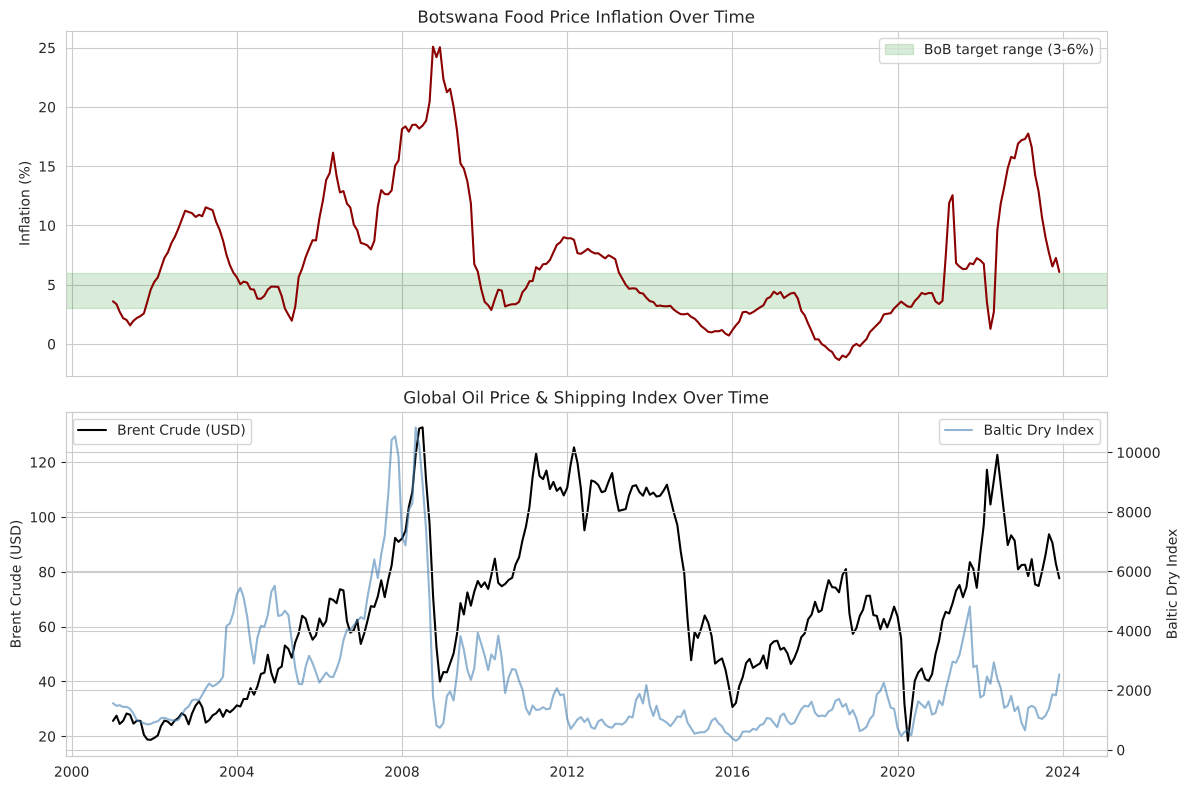

In [5]:
fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)

axes[0].plot(df["Date"], df["Food_Price_Inflation"], color="darkred")
axes[0].axhspan(3, 6, color="green", alpha=0.15, label="BoB target range (3-6%)")
axes[0].set_title("Botswana Food Price Inflation Over Time")
axes[0].set_ylabel("Inflation (%)")
axes[0].legend()

axes[1].plot(df["Date"], df["Brent_Crude_USD"], color="black", label="Brent Crude (USD)")
ax2 = axes[1].twinx()
ax2.plot(df["Date"], df["Baltic_Dry_Index_Avg"], color="steelblue", alpha=0.6, label="Baltic Dry Index")
axes[1].set_title("Global Oil Price & Shipping Index Over Time")
axes[1].set_ylabel("Brent Crude (USD)")
ax2.set_ylabel("Baltic Dry Index")
axes[1].legend(loc="upper left")
ax2.legend(loc="upper right")

plt.tight_layout()
plt.show()

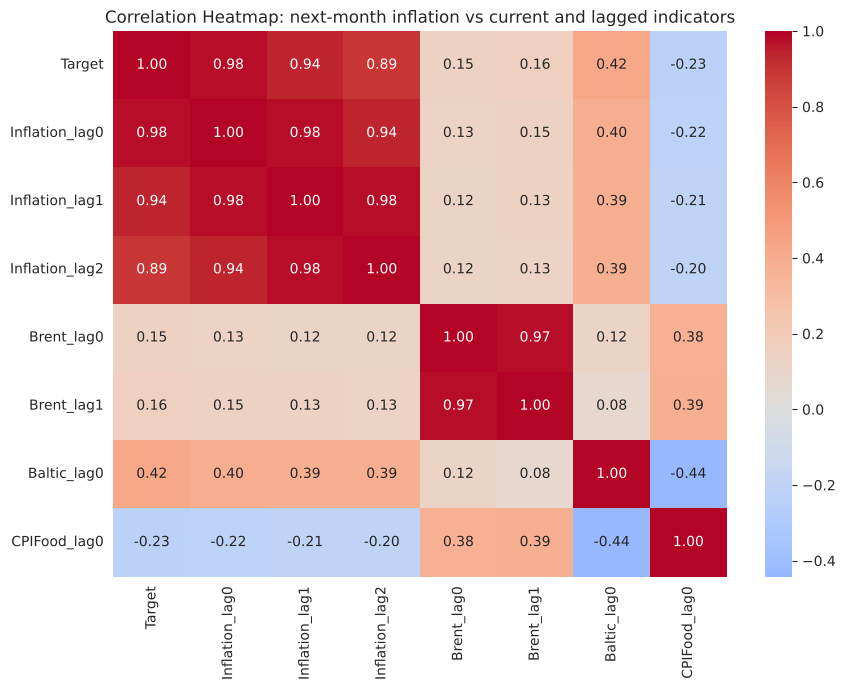

Correlation of each variable with next month's inflation (Target):
Inflation_lag0    0.978
Inflation_lag1    0.938
Inflation_lag2    0.891
Baltic_lag0       0.420
Brent_lag1        0.164
Brent_lag0        0.145
CPIFood_lag0     -0.233


In [6]:
corr_cols = ["Target", "Inflation_lag0", "Inflation_lag1", "Inflation_lag2",
             "Brent_lag0", "Brent_lag1", "Baltic_lag0", "CPIFood_lag0"]
corr = df_h1[corr_cols].corr()

plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation Heatmap: next-month inflation vs current and lagged indicators")
plt.tight_layout()
plt.show()

print("Correlation of each variable with next month's inflation (Target):")
print(corr["Target"].drop("Target").sort_values(ascending=False).round(3).to_string())

**Observation:** the printed correlations show how dominant inflation's own recent value is. Inflation_lag0 correlates 0.98 with next month's inflation (0.94 and 0.89 for lags 1 and 2), against 0.14 to 0.42 in absolute value for the oil, shipping and CPI-level variables. The high figures reflect the fact that year-on-year inflation overlaps by 11 of 12 months between neighbouring months, so it is partly a property of how the series is constructed. Because `CPIFood` is an index level that trends upward and inflation is computed from it, the two are not independent.

## Section 6: Turning Inflation Figures into Alert Categories

The Bank of Botswana's medium-term objective for inflation is the **3–6% range**. This is a policy objective, not a risk scale, and the Bank does not publish Low / Moderate / High labels. Any risk labels are therefore a choice made by this project, so the notebook runs **two schemes side by side** and checks whether the conclusions depend on the choice.

**Scheme A — position relative to the Bank's objective (primary).** Uses only the Bank's own numbers:
- **Below target**: inflation < 3%
- **Within target**: 3% to 6%
- **Above target**: inflation > 6% (this is the alert category)

**Scheme B — watch-zone bands (sensitivity check).** The scheme used in the earlier draft:
- **Low**: ≤ 6%, **Moderate**: 6–8% (a "watch" zone), **High**: > 8%. The 8% cut-off is a project choice with no official basis.

**Assumptions to state in the report.** The 3–6% objective is set for *headline* CPI inflation. Applying it to *food* inflation, which is usually more volatile, is a modelling choice and not an official rule. "Below target" is a description of where inflation sits, not a statement of risk.

In [7]:
def position_label(x):
    if x < 3:
        return "Below target"
    elif x <= 6:
        return "Within target"
    return "Above target"

def watch_zone_label(x):
    if x <= 6:
        return "Low"
    elif x <= 8:
        return "Moderate"
    return "High"

SCHEMES = {
    "A: Position vs 3-6% objective": dict(fn=position_label, labels=["Below target", "Within target", "Above target"]),
    "B: Watch-zone bands (6% / 8%)": dict(fn=watch_zone_label, labels=["Low", "Moderate", "High"]),
}
PRIMARY = "A: Position vs 3-6% objective"

for name, sch in SCHEMES.items():
    print(name, "- all months, h = 1:")
    print(df_h1["Target"].apply(sch["fn"]).value_counts().reindex(sch["labels"]).to_string(), "\n")

A: Position vs 3-6% objective - all months, h = 1:
Target
Below target      57
Within target     77
Above target     130 

B: Watch-zone bands (6% / 8%) - all months, h = 1:
Target
Low         134
Moderate     43
High         87 



## Section 7: Train / Validation / Test Split (Chronological)

Time-ordered data must be split chronologically. We use three windows, defined by the **month being forecast**:

| Window | Months forecast | Purpose |
|---|---|---|
| Train | 2001 – 2014 | fit candidate models |
| Validation | 2015 – 2018 | **choose** between models |
| Test | 2019 – 2023 | final scores, never used for any choice |

After choosing on validation, each model is refitted on train + validation (everything up to 2018) and scored once on the test window, which includes the COVID-era and the 2022 global inflation shock.

Caveat: the 2015–2018 validation window is calm (inflation mostly between 0% and 5%), so it favours simple models. Validation scores are therefore a rough guide only.

In [8]:
def split_windows(d):
    tr    = d[d["TargetDate"] <= "2014-12-01"]
    va    = d[(d["TargetDate"] > "2014-12-01") & (d["TargetDate"] <= "2018-12-01")]
    trva  = d[d["TargetDate"] <= "2018-12-01"]
    te    = d[(d["TargetDate"] > "2018-12-01") & (d["TargetDate"] <= "2023-12-01")]
    return tr, va, trva, te

tr, va, trva, te = split_windows(df_h1)
for name, part in [("Train", tr), ("Validation", va), ("Train+Validation", trva), ("Test", te)]:
    print(f"{name:17s} n={len(part):3d}  forecast months {part['TargetDate'].min().date()} to {part['TargetDate'].max().date()}")

Train             n=156  forecast months 2002-01-01 to 2014-12-01
Validation        n= 48  forecast months 2015-01-01 to 2018-12-01
Train+Validation  n=204  forecast months 2002-01-01 to 2018-12-01
Test              n= 60  forecast months 2019-01-01 to 2023-12-01


## Section 8: Stage 1 — Regression Modelling, Against Naive Benchmarks

For each horizon (1, 2, 3 months) and each of three feature sets, we fit Linear Regression, Random Forest and XGBoost. Each model is:
1. fitted on the train window and scored on the validation window (used only to choose),
2. refitted on train + validation and scored once on the test window.

We also score the two naive rules on the same months. A model is only useful if it beats the naive rule it is competing with.

In [9]:
def rmse(a, b): return float(np.sqrt(mean_squared_error(a, b)))

def make_models():
    return {
        "Linear Regression": LinearRegression(),
        "Random Forest": RandomForestRegressor(n_estimators=200, max_depth=4, min_samples_leaf=5, random_state=42, n_jobs=1),
        "XGBoost": XGBRegressor(n_estimators=100, max_depth=3, learning_rate=0.05, random_state=42),
    }

rows, test_preds, test_info = [], {}, {}
for h in HORIZONS:
    d = add_features(df, h)
    tr, va, trva, te = split_windows(d)
    test_info[h] = te[["Date", "TargetDate", "Target"]].copy()

    for label, col in [("Naive: last value", "Naive_last_value"), ("Naive: same month last year", "Naive_same_month_last_year")]:
        rows.append(dict(Horizon=h, Model=label, Features="none",
                         Val_RMSE=rmse(va["Target"], va[col]), Test_RMSE=rmse(te["Target"], te[col]),
                         Test_MAE=mean_absolute_error(te["Target"], te[col]), Test_R2=r2_score(te["Target"], te[col])))
        test_preds[(h, label, "none")] = te[col].values

    for kind in FEATURE_SETS:
        F = feature_list(kind)
        for name in make_models():
            m = make_models()[name].fit(tr[F], tr["Target"])
            val = rmse(va["Target"], m.predict(va[F]))
            m2 = make_models()[name].fit(trva[F], trva["Target"])
            p = m2.predict(te[F])
            rows.append(dict(Horizon=h, Model=name, Features=kind, Val_RMSE=val, Test_RMSE=rmse(te["Target"], p),
                             Test_MAE=mean_absolute_error(te["Target"], p), Test_R2=r2_score(te["Target"], p)))
            test_preds[(h, name, kind)] = p

results = pd.DataFrame(rows)
pd.set_option("display.width", 200)
print(results.round(3).to_string(index=False))

 Horizon                       Model       Features  Val_RMSE  Test_RMSE  Test_MAE  Test_R2
       1           Naive: last value           none     0.377      1.684     0.987    0.892
       1 Naive: same month last year           none     2.612      6.021     4.699   -0.386
       1           Linear Regression           full     1.156      1.649     0.945    0.896
       1               Random Forest           full     2.000      1.775     1.075    0.880
       1                     XGBoost           full     2.668      1.931     1.232    0.857
       1           Linear Regression drivers_no_cpi     0.339      1.631     0.889    0.898
       1               Random Forest drivers_no_cpi     2.018      1.759     1.067    0.882
       1                     XGBoost drivers_no_cpi     3.057      1.711     0.984    0.888
       1           Linear Regression inflation_only     0.385      1.633     0.874    0.898
       1               Random Forest inflation_only     2.003      1.737     1.0

### Choosing the model on the validation window

Both the model **and the feature set** are chosen on the validation window: of the nine candidates (3 models × 3 feature sets), the one with the lowest *validation* RMSE is selected for each horizon. This answers a review point that the food CPI level should either be dropped or be judged on validation results. Its test score is then reported next to the naive benchmark, and the feature set it prefers becomes the main feature set (`MAIN`) for the rest of the notebook.

In [10]:
summary = []
for h in HORIZONS:
    cand = results[(results["Horizon"] == h) & (results["Features"] != "none")]
    pick = cand.loc[cand["Val_RMSE"].idxmin()]          # joint choice of model AND feature set, on validation only
    nv = results[(results["Horizon"] == h) & (results["Model"] == "Naive: last value")].iloc[0]
    best_any = cand.sort_values("Test_RMSE").iloc[0]
    summary.append(dict(Horizon=h,
        Picked_on_validation=pick["Model"], Picked_features=pick["Features"], Picked_Val_RMSE=pick["Val_RMSE"],
        Picked_Test_RMSE=pick["Test_RMSE"], Picked_Test_R2=pick["Test_R2"],
        Naive_Test_RMSE=nv["Test_RMSE"], Naive_Test_R2=nv["Test_R2"],
        Change_vs_naive_pct=(pick["Test_RMSE"] / nv["Test_RMSE"] - 1) * 100,
        Best_test_RMSE_any=best_any["Test_RMSE"], Best_any_model=f"{best_any['Model']} / {best_any['Features']}"))
summary = pd.DataFrame(summary)
print(summary.round(3).to_string(index=False))
picked = {int(r.Horizon): r.Picked_on_validation for r in summary.itertuples()}
picked_fs = {int(r.Horizon): r.Picked_features for r in summary.itertuples()}
MAIN = summary["Picked_features"].mode()[0]     # the feature set validation prefers; used for everything that follows
print("\nPicked models:", picked)
print("Picked feature sets:", picked_fs)
print("Main feature set from here on:", MAIN, "->", feature_list(MAIN))

 Horizon Picked_on_validation Picked_features  Picked_Val_RMSE  Picked_Test_RMSE  Picked_Test_R2  Naive_Test_RMSE  Naive_Test_R2  Change_vs_naive_pct  Best_test_RMSE_any                     Best_any_model
       1    Linear Regression  drivers_no_cpi            0.339             1.631           0.898            1.684          0.892               -3.157               1.631 Linear Regression / drivers_no_cpi
       2    Linear Regression  drivers_no_cpi            0.603             2.870           0.685            2.836          0.692                1.170               2.674           XGBoost / drivers_no_cpi
       3    Linear Regression  drivers_no_cpi            0.927             3.740           0.465            3.604          0.503                3.779               3.332           XGBoost / drivers_no_cpi

Picked models: {1: 'Linear Regression', 2: 'Linear Regression', 3: 'Linear Regression'}
Picked feature sets: {1: 'drivers_no_cpi', 2: 'drivers_no_cpi', 3: 'drivers_no_cpi'}
Main f

**Result.**

| Horizon | Naive: last value (RMSE / R²) | Model and feature set picked on validation (RMSE / R²) | Lowest test RMSE of any candidate (chosen after seeing the test set) |
|---|---|---|---|
| 1 month | 1.68 / 0.89 | Linear Regression, drivers without CPI: 1.63 / 0.90 | 1.63 (the same model) |
| 2 months | 2.84 / 0.69 | Linear Regression, drivers without CPI: 2.87 / 0.69 | 2.67 (XGBoost, drivers without CPI) |
| 3 months | 3.60 / 0.50 | Linear Regression, drivers without CPI: 3.74 / 0.46 | 3.33 (XGBoost, drivers without CPI) |

Validation picks the same model and feature set (Linear Regression, inflation plus Brent and Baltic lags, **no CPI level**) at every horizon, so this becomes the main feature set for the rest of the notebook. On the test window the picked model is 3.2% more accurate than the naive rule at 1 month, but 1.2% worse at 2 months and 3.8% worse at 3 months. The right-hand column picks the best of nine candidates on the test set itself, so it is optimistic by construction and is not evidence that XGBoost is better; Section 15 tests this properly. The earlier notebook's headline (Random Forest, R² 0.684, RMSE 2.85) was in effect a 2-month forecast and matches the 2-month naive rule (R² 0.69, RMSE 2.84).

### Where do the errors occur?

An overall R² can hide behaviour at turning points. Below we compare errors in months where inflation moved sharply over the previous three months (a change of 3 percentage points or more) with all other months.

In [11]:
h = 1
d = add_features(df, h)
_, _, _, te = split_windows(d)
sharp = (te["Food_Price_Inflation"] - df.set_index("Date").loc[te["Date"] - pd.DateOffset(months=3), "Food_Price_Inflation"].values).abs() >= 3
sharp = sharp.values

pk = picked[1]
p_model = test_preds[(1, pk, picked_fs[1])]
p_naive = test_preds[(1, "Naive: last value", "none")]
y = te["Target"].values
tbl = pd.DataFrame({
    "Months": ["Sharp-move months", "Other months"],
    "n": [sharp.sum(), (~sharp).sum()],
    f"MAE {pk}": [np.abs(y - p_model)[sharp].mean(), np.abs(y - p_model)[~sharp].mean()],
    "MAE Naive (last value)": [np.abs(y - p_naive)[sharp].mean(), np.abs(y - p_naive)[~sharp].mean()],
})
print(tbl.round(2).to_string(index=False))

           Months  n  MAE Linear Regression  MAE Naive (last value)
Sharp-move months 19                   1.59                    1.92
     Other months 41                   0.57                    0.55


Errors are about three times larger in sharp-move months. For the 1-month Linear Regression, MAE is 1.59 in the 19 sharp-move months against 0.57 in the other 41; the naive rule scores 1.92 and 0.55. The model is somewhat better than the naive rule at turning points and about equal elsewhere. Whatever the model does well or badly overall is decided by a small number of turning points (early 2021, early 2022, the 2023 decline), so any single score should be read with that in mind.

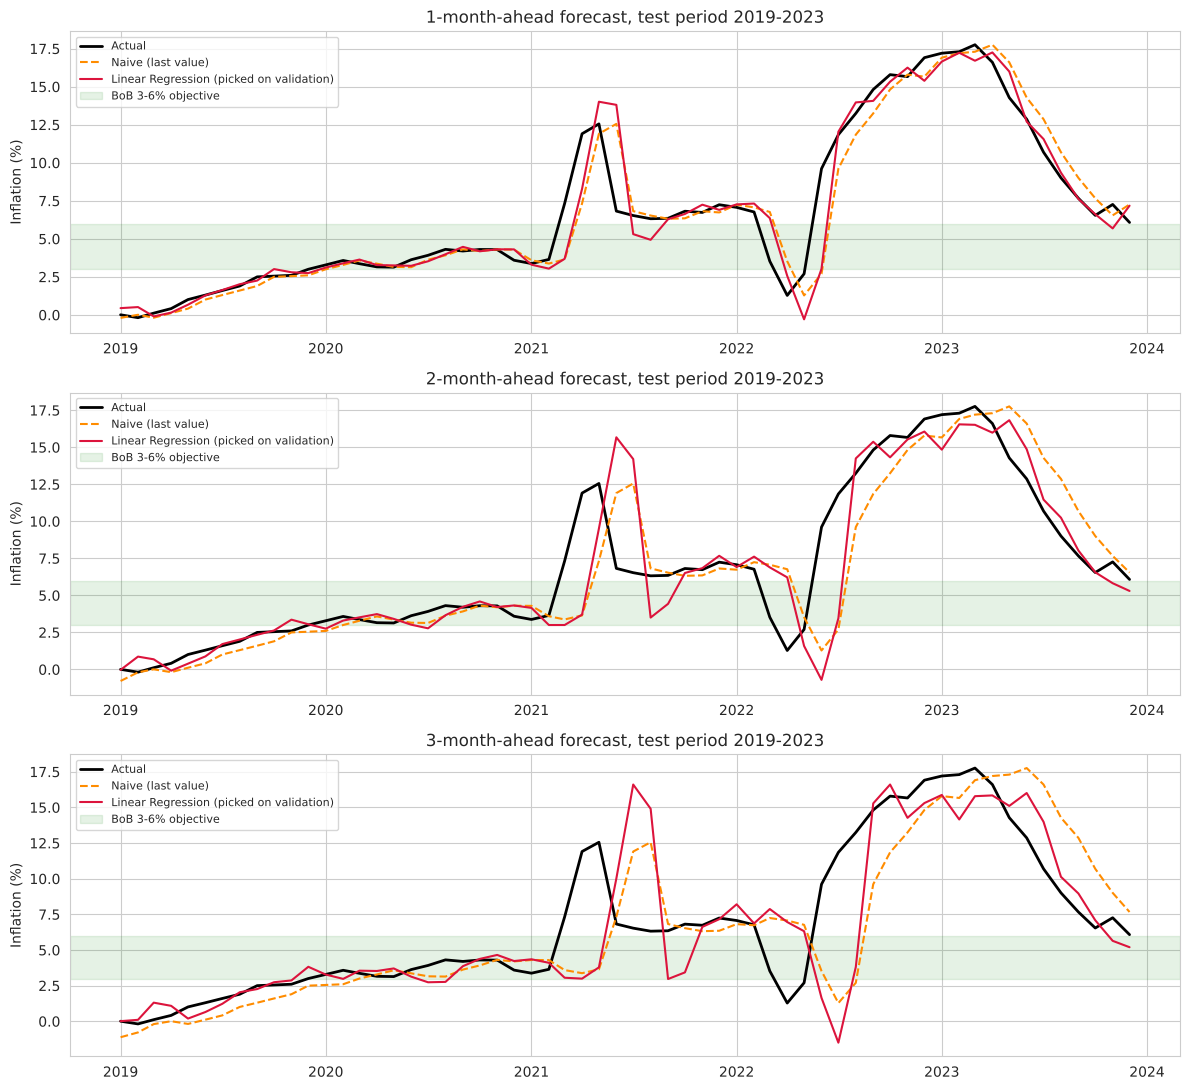

In [12]:
fig, axes = plt.subplots(3, 1, figsize=(12, 11), sharex=False)
for ax, h in zip(axes, HORIZONS):
    info = test_info[h]
    ax.plot(info["TargetDate"], info["Target"], color="black", lw=2, label="Actual")
    ax.plot(info["TargetDate"], test_preds[(h, "Naive: last value", "none")], color="darkorange", ls="--", label="Naive (last value)")
    ax.plot(info["TargetDate"], test_preds[(h, picked[h], picked_fs[h])], color="crimson", label=f"{picked[h]} (picked on validation)")
    ax.axhspan(3, 6, color="green", alpha=0.1, label="BoB 3-6% objective")
    ax.set_title(f"{h}-month-ahead forecast, test period 2019-2023")
    ax.set_ylabel("Inflation (%)")
    ax.legend(loc="upper left", fontsize=8)
plt.tight_layout()
plt.show()

**Observation:** the model line and the naive line sit almost on top of each other. Both trail the actual series at sharp turns: when inflation jumps, a forecast built from past values cannot know about it until it has happened. The wider the horizon, the larger that lag. Tree-based models also cannot predict values outside the range seen in training, which matters for the 2022–2023 peak.

## Section 9: Do Oil, Shipping and CPI Add Anything? (Feature-Set Comparison)

The table below shows test RMSE for each feature set, side by side with the naive rule, at each horizon. If the extra variables mattered, "All features" and "Drivers, no CPI" would be clearly lower than "Own inflation history only".

In [13]:
ml = results[results["Features"] != "none"].copy()
ml["Feature set"] = ml["Features"].map(FEATURE_SETS)
pivot = ml.pivot_table(index=["Horizon", "Model"], columns="Feature set", values="Test_RMSE")
naive_rmse = results[results["Model"] == "Naive: last value"].set_index("Horizon")["Test_RMSE"]
pivot["Naive: last value"] = [naive_rmse[h] for h, _ in pivot.index]
print("Test RMSE by feature set (lower is better):")
print(pivot.round(2).to_string())

Test RMSE by feature set (lower is better):
Feature set                All features  Drivers, no CPI level  Own inflation history only  Naive: last value
Horizon Model                                                                                                
1       Linear Regression          1.65                   1.63                        1.63               1.68
        Random Forest              1.77                   1.76                        1.74               1.68
        XGBoost                    1.93                   1.71                        1.71               1.68
2       Linear Regression          2.90                   2.87                        2.91               2.84
        Random Forest              2.83                   2.81                        2.76               2.84
        XGBoost                    3.37                   2.67                        2.74               2.84
3       Linear Regression          3.87                   3.74              

**Observation:** dropping the food CPI level lowers test RMSE in all nine model-by-horizon cells (for example XGBoost at 1 month, 1.93 to 1.71), and validation also prefers the version without it (Section 8). The CPI level is therefore dropped from the main feature set. A plausible reason is that it is a trending index from which inflation itself is computed, but this was not tested. Neither oil, shipping nor CPI inputs make the models clearly better than "Own inflation history only".

## Section 10: Stage 2 — Risk Classification

Two ways of producing a category label are compared on the same test months, and each is run under both schemes from Section 6:

- **Method 1 (threshold):** forecast the number, then apply the category cut-offs from Section 6. We do this for the naive rule and for each regression model.
- **Method 2 (direct):** train a classifier on the labels. Logistic Regression (scaled) and Random Forest Classifier, both with `class_weight="balanced"`, using the main feature set chosen in Section 8.

Metrics: overall accuracy, weighted F1, and **recall for each class** (lower, middle and upper class of each scheme). For an early-warning system, recall for the upper class (Above target, or High) matters most, and weighted averages hide it.

In [14]:
test_labels, clf_rows, cms = {}, [], {}
for h in HORIZONS:
    d = add_features(df, h)
    tr, va, trva, te = split_windows(d)
    F = feature_list(MAIN)
    sc = StandardScaler().fit(trva[F])
    direct = {"Logistic Regression (direct)": LogisticRegression(max_iter=3000, class_weight="balanced"),
              "Random Forest Classifier (direct)": RandomForestClassifier(n_estimators=200, max_depth=5, min_samples_leaf=5, random_state=42, n_jobs=1, class_weight="balanced")}
    for sname, sch in SCHEMES.items():
        fn, LBL = sch["fn"], sch["labels"]
        y_true = te["Target"].apply(fn).values
        test_labels[(sname, h)] = y_true

        sets = {"Naive: last value (threshold)": test_preds[(h, "Naive: last value", "none")]}
        for name in make_models():
            sets[f"{name} (threshold)"] = test_preds[(h, name, MAIN)]
        preds_by_method = {k: np.array([fn(x) for x in p]) for k, p in sets.items()}

        y_tr = trva["Target"].apply(fn).values
        for k, m in direct.items():
            m.fit(sc.transform(trva[F]), y_tr)
            preds_by_method[k] = m.predict(sc.transform(te[F]))

        for k, pc in preds_by_method.items():
            r = recall_score(y_true, pc, labels=LBL, average=None, zero_division=0)
            clf_rows.append(dict(Scheme=sname, Horizon=h, Method=k, Accuracy=accuracy_score(y_true, pc),
                                 F1_weighted=f1_score(y_true, pc, average="weighted", zero_division=0),
                                 Recall_Lower=r[0], Recall_Middle=r[1], Recall_Upper=r[2]))
            cms[(sname, h, k)] = confusion_matrix(y_true, pc, labels=LBL)

clf_results = pd.DataFrame(clf_rows)
for sname, sch in SCHEMES.items():
    print(f"=== Scheme {sname}")
    print("Test class counts:", dict(pd.Series(test_labels[(sname, 1)]).value_counts().reindex(sch["labels"])))
    print("(Recall_Lower / Middle / Upper = " + " / ".join(sch["labels"]) + ")")
    print(clf_results[clf_results["Scheme"] == sname].drop(columns="Scheme").round(3).to_string(index=False), "\n")

=== Scheme A: Position vs 3-6% objective
Test class counts: {'Below target': np.int64(13), 'Within target': np.int64(16), 'Above target': np.int64(31)}
(Recall_Lower / Middle / Upper = Below target / Within target / Above target)
 Horizon                            Method  Accuracy  F1_weighted  Recall_Lower  Recall_Middle  Recall_Upper
       1     Naive: last value (threshold)     0.917        0.917         0.923          0.875         0.935
       1     Linear Regression (threshold)     0.867        0.871         0.923          0.875         0.839
       1         Random Forest (threshold)     0.917        0.917         0.923          0.875         0.935
       1               XGBoost (threshold)     0.900        0.901         0.923          0.812         0.935
       1      Logistic Regression (direct)     0.683        0.694         0.846          0.438         0.742
       1 Random Forest Classifier (direct)     0.883        0.884         0.846          0.812         0.935
       

classification_report, Linear Regression thresholded, h = 1, scheme A: Position vs 3-6% objective:
               precision    recall  f1-score   support

 Below target       0.92      0.92      0.92        13
Within target       0.70      0.88      0.78        16
 Above target       0.96      0.84      0.90        31

     accuracy                           0.87        60
    macro avg       0.86      0.88      0.87        60
 weighted avg       0.88      0.87      0.87        60

classification_report, Linear Regression thresholded, h = 1, scheme B: Watch-zone bands (6% / 8%):
              precision    recall  f1-score   support

         Low       0.85      0.97      0.90        29
    Moderate       0.90      0.64      0.75        14
        High       0.94      0.94      0.94        17

    accuracy                           0.88        60
   macro avg       0.90      0.85      0.86        60
weighted avg       0.89      0.88      0.88        60



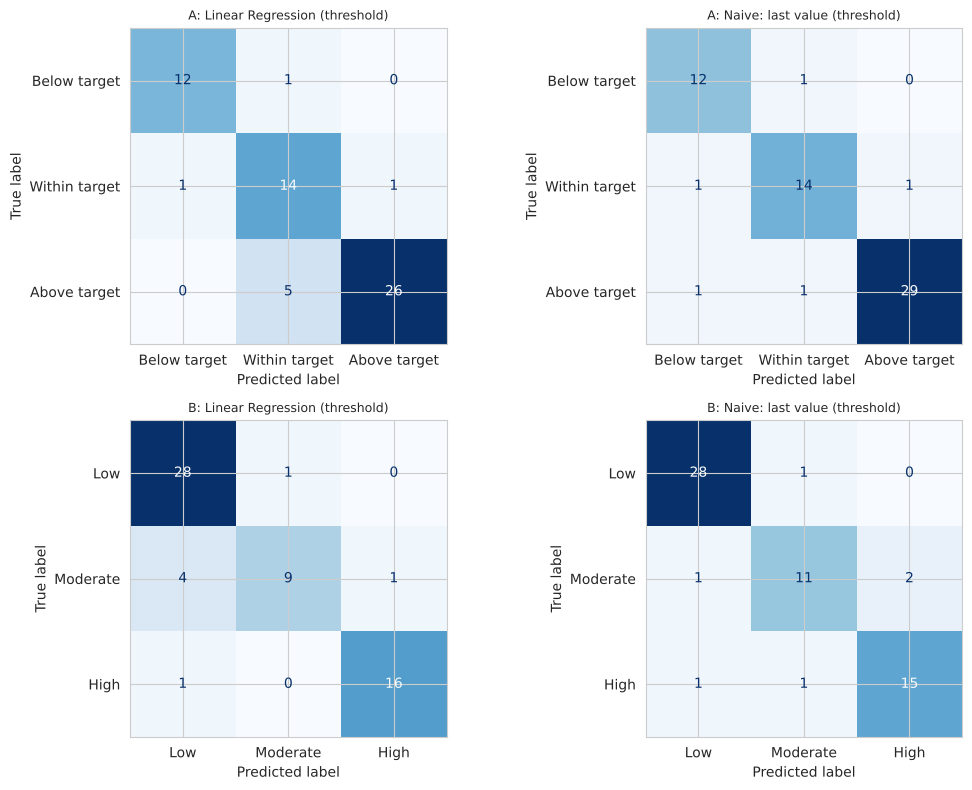

In [15]:
h = 1
pk = picked[h]
p = test_preds[(h, pk, picked_fs[h])]
for sname, sch in SCHEMES.items():
    pc = np.array([sch["fn"](x) for x in p])
    print(f"classification_report, {pk} thresholded, h = {h}, scheme {sname}:")
    print(classification_report(test_labels[(sname, h)], pc, labels=sch["labels"], zero_division=0))

fig, axes = plt.subplots(2, 2, figsize=(11, 8))
for row, (sname, sch) in zip(axes, SCHEMES.items()):
    for ax, k in zip(row, [f"{pk} (threshold)", "Naive: last value (threshold)"]):
        ConfusionMatrixDisplay(cms[(sname, h, k)], display_labels=sch["labels"]).plot(ax=ax, cmap="Blues", colorbar=False)
        ax.set_title(f"{sname[:1]}: {k}", fontsize=9)
plt.tight_layout()
plt.show()

**Result (classification), main feature set.**

Scheme A, position relative to the 3–6% objective (test months: 13 Below target, 16 Within target, 31 Above target):
- At 1 month, the naive rule and thresholded Random Forest both reach 91.7% accuracy, and each flags 93.5% of Above-target months (29 of 31). Thresholded XGBoost matches that recall with 90.0% accuracy, and thresholded Linear Regression reaches 86.7% accuracy and catches 83.9%.
- The direct Random Forest Classifier reaches 88.3% accuracy and also flags 93.5% of Above-target months. The direct Logistic Regression is weaker (68.3% accuracy, 74.2% Above-target recall).

Scheme B, watch-zone bands (29 Low, 14 Moderate, 17 High): at 1 month the naive rule, thresholded Random Forest and thresholded XGBoost score 90.0% accuracy and 88.2% High recall. Thresholded Linear Regression scores 88.3% and flags 94.1% of High months but only 64.3% of Moderate months. Both direct classifiers score 86.7% to 88.3%, with 82.4% High recall.

**What holds under both schemes.**
- At 1 and 2 months, no method is more accurate than the naive rule (several tie it). At 3 months the naive rule is also best, except thresholded Random Forest under Scheme A (81.7% against 80.0%, a difference of one month out of 60).
- At every horizon, the best thresholded method is at least as accurate as the best direct classifier in both schemes (for example 91.7% against 88.3% at 1 month under Scheme A). A plausible reason is that a regression forecast keeps the size of the numbers, but this was not tested.
- The accuracy of all methods falls as the horizon lengthens (naive: 91.7%, 85.0%, 80.0% for Scheme A).

**What depends on the scheme or the feature set.** Thresholded Linear Regression flags fewer Above-target months than the naive rule under Scheme A (83.9% against 93.5%) but more High months under Scheme B (94.1% against 88.2%), so class-level conclusions should be stated for the scheme chosen. Earlier versions of this notebook, which used the food CPI level, found that the direct classifiers collapsed (for example, the direct Logistic Regression reached only 35.0% accuracy under Scheme A). That failure disappears once the CPI level is dropped, which suggests the trending CPI level was responsible, but this was not tested separately.

The test set is small (60 months), so one or two months change a recall figure by several points. The two-stage design works as a way to produce category labels, but the numbers do not show that its regression stage beats the naive rule.

## Section 11: What Is the Model Relying On?

Feature importance for the 1-month Random Forest with the main feature set, grouped by variable family.

Importance by variable family:
Inflation    99.34%
Brent         0.51%
Baltic        0.15%

Top 5 individual features:
Inflation_lag0    0.9823
Inflation_lag1    0.0090
Inflation_lag2    0.0021
Brent_lag2        0.0021
Brent_lag0        0.0017


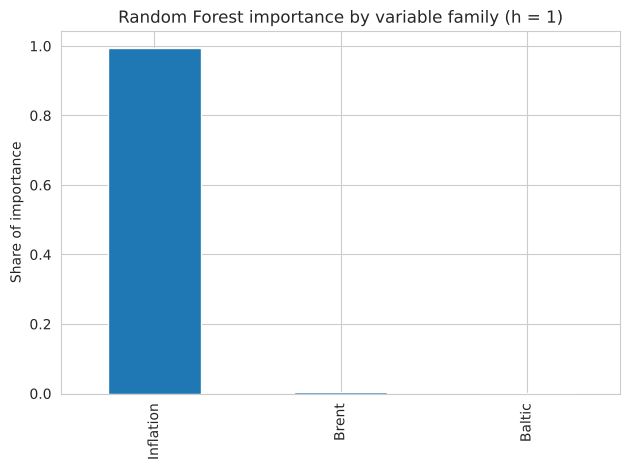

In [16]:
F = feature_list(MAIN)
d = add_features(df, 1)
_, _, trva, _ = split_windows(d)
rf = make_models()["Random Forest"].fit(trva[F], trva["Target"])
imp = pd.Series(rf.feature_importances_, index=F)
group = imp.groupby(lambda c: c.split("_lag")[0]).sum().sort_values(ascending=False)
print("Importance by variable family:")
print((group * 100).round(2).astype(str).add("%").to_string())
print("\nTop 5 individual features:")
print(imp.sort_values(ascending=False).head(5).round(4).to_string())
group.plot(kind="bar", title="Random Forest importance by variable family (h = 1)", ylabel="Share of importance")
plt.tight_layout()
plt.show()

**Observation:** past inflation carries about 99% of the importance. Brent crude is next at roughly 0.5%. The policy rate is not in the model (excluded, Section 3). This agrees with Section 9: the model is essentially extrapolating inflation's own recent value, and the other indicators are not used in a meaningful way. That is a result in itself. It does not show that oil and shipping do not matter for food prices in Botswana, only that they add nothing to short-horizon forecasts once recent inflation is known.

## Section 12: Export Results for the Dashboard

We save the test-period predictions for every horizon (actual, naive, and each model with the main feature set) together with the results tables.

In [17]:
frames = []
for h in HORIZONS:
    info = test_info[h].rename(columns={"Date": "Forecast_Origin", "Target": "Actual_Inflation"}).copy()
    info["Horizon_Months"] = h
    info["Naive_Last_Value"] = test_preds[(h, "Naive: last value", "none")]
    for name in make_models():
        info[f"Pred_{name.replace(' ', '_')}"] = test_preds[(h, name, MAIN)]
    info["Actual_Position_vs_Target"] = test_labels[(PRIMARY, h)]
    info["Actual_Watch_Zone"] = test_labels[("B: Watch-zone bands (6% / 8%)", h)]
    frames.append(info)
export = pd.concat(frames, ignore_index=True)
export.to_csv("model_predictions_for_dashboard.csv", index=False)
results.to_csv("regression_results_all.csv", index=False)
clf_results.to_csv("classification_results_all.csv", index=False)
print("Exported: model_predictions_for_dashboard.csv, regression_results_all.csv, classification_results_all.csv")
export.head()

Exported: model_predictions_for_dashboard.csv, regression_results_all.csv, classification_results_all.csv


,Forecast_Origin,TargetDate,Actual_Inflation,Horizon_Months,Naive_Last_Value,Pred_Linear_Regression,Pred_Random_Forest,Pred_XGBoost,Actual_Position_vs_Target,Actual_Watch_Zone
0,2018-12-01,2019-01-01,0.007429,1,-0.195886,0.444847,-0.199788,-0.493613,Below target,Low
1,2019-01-01,2019-02-01,-0.183642,1,0.007429,0.514221,-0.038837,-0.101914,Below target,Low
2,2019-02-01,2019-03-01,0.115759,1,-0.183642,-0.098990,0.117298,-0.362995,Below target,Low
3,2019-03-01,2019-04-01,0.414577,1,0.115759,0.149786,-0.018209,-0.101914,Below target,Low
4,2019-04-01,2019-05-01,1.008746,1,0.414577,0.670332,-0.116834,0.561307,Below target,Low


---
### Summary of Stage 1 and Stage 2

- **Regression (Stage 1):** food price inflation was forecast 1, 2 and 3 months ahead from lags 0–2 of inflation, Brent crude and the Baltic Dry Index. The food CPI level was dropped because validation preferred the version without it, and the policy rate was excluded because a verified series could not be obtained. On the 2019–2023 test months, the model picked on validation (Linear Regression) scored RMSE 1.63, 2.87 and 3.74 at the three horizons, against 1.68, 2.84 and 3.60 for the naive rule of repeating the last known value.
- **Rolling origins and Diebold–Mariano tests (Section 15):** on 60 rolling forecast origins per horizon, no model was significantly more accurate than the naive rule at any horizon (the smallest one-sided p-value was 0.17), and Random Forest at 1 month was significantly worse (p = 0.04). The data therefore do not show that any model beats the baseline.
- **What this means:** the models learn that inflation is persistent. They do not show added value from oil, shipping or CPI inputs. The policy rate was excluded, so nothing is concluded about it. The earlier notebook's R² of 0.684 was a 2-month forecast and equals the naive 2-month score.
- **Classification (Stage 2):** converting a forecast into alert categories was tested under two schemes. Under Scheme A (below / within / above the Bank's 3–6% objective), thresholded forecasts reach 87–92% accuracy at 1 month and flag 84–94% of Above-target months. Under Scheme B (the 6% / 8% watch-zone bands) they reach 88–90% and flag 88–94% of High months. Under both, the naive rule is as accurate as the best model at 1 and 2 months and, bar one month in Scheme A, at 3 months, and thresholding a forecast is at least as good as classifying directly.
- **Both stages together** form the two-stage early warning system described in the project's Terms of Reference, with the limitation that Stage 1 adds little beyond persistence.

## Section 13: Regional Data — Testing All Four Countries

An earlier review of the project raised two points:

1. The project title and aim refer to **regional indicators**, yet up to this point the model used only Botswana and global data. Neighbouring countries needed to be tested.
2. All four available countries (Kenya, Namibia, South Africa, Zimbabwe) should be tested, including Zimbabwe, and any exclusion should come from the results and not be assumed beforehand.

Below we rebuild the regional features on the corrected setup: lags 0–2, the 1-month **and 3-month** horizons (a review point noted that an early-warning signal matters most at the longer horizon), the main feature set from Section 8, and the same train / validation / test windows. We use each neighbour's **food inflation only**. Their CPI index levels are dropped, because those levels trend upward with very different scales (Zimbabwe's reaches extreme values) and caused the earlier linear model to fail numerically.

In [18]:
regional_countries = ["Kenya", "Namibia", "South Africa", "Zimbabwe"]

pr = panel[panel["Country"].isin(regional_countries)][["Date", "Country", "Food_Price_Inflation"]]
reg_wide = pr.pivot(index="Date", columns="Country", values="Food_Price_Inflation")
reg_wide.columns = [c.replace(" ", "_") + "_Infl" for c in reg_wide.columns]
reg_wide = reg_wide.reset_index()

print("Neighbour food inflation, summary statistics (%):")
print(reg_wide.drop(columns="Date").describe().round(1).T.to_string())
print("\nBotswana, for comparison:")
print(df["Food_Price_Inflation"].describe().round(1).to_string())

Neighbour food inflation, summary statistics (%):
                   count  mean    std   min  25%  50%   75%    max
Kenya_Infl         276.0  10.4    6.2  -1.2  6.1  9.8  13.4   26.2
Namibia_Infl       276.0   7.5    4.5  -1.9  4.4  7.0  10.5   18.9
South_Africa_Infl  276.0   7.2    4.6   0.4  3.8  6.2   9.9   21.8
Zimbabwe_Infl      276.0  65.0  177.4 -14.1  1.7  1.8   7.4  980.4

Botswana, for comparison:
count    276.0
mean       6.9
std        5.4
min       -1.4
25%        3.2
50%        5.2
75%        9.2
max       25.1


In [19]:
def add_regional(d, h, countries):
    out = add_features(df, h).merge(reg_wide, on="Date", how="left")
    extra = []
    for c in countries:
        s = c.replace(" ", "_") + "_Infl"
        for l in LAGS:
            out[f"{s}_lag{l}"] = out[s].shift(l)
            extra.append(f"{s}_lag{l}")
    return out.dropna().reset_index(drop=True), extra

def zim_capped(d):
    d = d.copy()
    for l in LAGS:
        d[f"Zimbabwe_Infl_lag{l}"] = d[f"Zimbabwe_Infl_lag{l}"].clip(-20, 50)
    return d

REG_H = [1, 3]
reg_rows, naive_reg = [], {}
variants = {
    "A: Baseline (no regional)":            [],
    "B: + all 4 countries":                 regional_countries,
    "C: + 3 countries (no Zimbabwe)":       ["Kenya", "Namibia", "South Africa"],
    "D: + all 4, Zimbabwe capped at 50%":   regional_countries,
}
for h in REG_H:
    for label, ctry in variants.items():
        d, extra = add_regional(df, h, ctry)
        if label.startswith("D"):
            d = zim_capped(d)
        tr_, va_, trva_, te_ = split_windows(d)
        F = feature_list(MAIN) + extra
        for name in make_models():
            m = make_models()[name].fit(trva_[F], trva_["Target"])
            p = m.predict(te_[F])
            reg_rows.append(dict(Horizon=h, Version=label, Model=name, RMSE=rmse(te_["Target"], p),
                                 MAE=mean_absolute_error(te_["Target"], p), R2=r2_score(te_["Target"], p)))
    naive_reg[h] = (rmse(te_["Target"], te_["Naive_last_value"]), r2_score(te_["Target"], te_["Naive_last_value"]))
reg_cmp = pd.DataFrame(reg_rows)
for h in REG_H:
    print(f"Test results, h = {h} (lower RMSE is better):")
    print(reg_cmp[reg_cmp["Horizon"] == h].drop(columns="Horizon").round(3).to_string(index=False))
    print(f"Naive last-value benchmark on the same months: RMSE {naive_reg[h][0]:.3f}, R2 {naive_reg[h][1]:.3f}\n")
reg_cmp.to_csv("regional_ablation_results.csv", index=False)

Test results, h = 1 (lower RMSE is better):
                           Version             Model  RMSE   MAE     R2
         A: Baseline (no regional) Linear Regression 1.631 0.889  0.898
         A: Baseline (no regional)     Random Forest 1.759 1.067  0.882
         A: Baseline (no regional)           XGBoost 1.711 0.984  0.888
              B: + all 4 countries Linear Regression 9.383 6.833 -2.367
              B: + all 4 countries     Random Forest 1.817 1.146  0.874
              B: + all 4 countries           XGBoost 1.782 1.114  0.879
    C: + 3 countries (no Zimbabwe) Linear Regression 1.586 0.865  0.904
    C: + 3 countries (no Zimbabwe)     Random Forest 1.795 1.122  0.877
    C: + 3 countries (no Zimbabwe)           XGBoost 1.825 1.175  0.873
D: + all 4, Zimbabwe capped at 50% Linear Regression 1.853 1.402  0.869
D: + all 4, Zimbabwe capped at 50%     Random Forest 1.817 1.146  0.874
D: + all 4, Zimbabwe capped at 50%           XGBoost 1.782 1.114  0.879
Naive last-value ben

## Section 14: One Country at a Time, and Feature Importance

In [20]:
rows = []
for h in REG_H:
    for c in regional_countries:
        d, extra = add_regional(df, h, [c])
        tr_, va_, trva_, te_ = split_windows(d)
        F = feature_list(MAIN) + extra
        for name in make_models():
            m = make_models()[name].fit(trva_[F], trva_["Target"])
            p = m.predict(te_[F])
            rows.append(dict(Horizon=h, Added_country=c, Model=name, RMSE=rmse(te_["Target"], p), R2=r2_score(te_["Target"], p)))
one = pd.DataFrame(rows)
base = reg_cmp[reg_cmp["Version"].str.startswith("A")].set_index(["Horizon", "Model"])["RMSE"]
one["RMSE_change_vs_baseline_pct"] = [(r.RMSE / base[(r.Horizon, r.Model)] - 1) * 100 for r in one.itertuples()]
print(one.round(3).to_string(index=False))

for h in REG_H:
    d, extra = add_regional(df, h, regional_countries)
    _, _, trva_, _ = split_windows(d)
    F = feature_list(MAIN) + extra
    rf_r = make_models()["Random Forest"].fit(trva_[F], trva_["Target"])
    imp_r = pd.Series(rf_r.feature_importances_, index=F)
    print(f"\nRandom Forest importance by regional country, h = {h} (all lags combined):")
    for c in regional_countries:
        k = c.replace(" ", "_") + "_Infl"
        print(f"  {c:13s}: {imp_r[[i for i in F if i.startswith(k)]].sum()*100:5.2f}%")

 Horizon Added_country             Model   RMSE      R2  RMSE_change_vs_baseline_pct
       1         Kenya Linear Regression  1.622   0.899                       -0.531
       1         Kenya     Random Forest  1.756   0.882                       -0.141
       1         Kenya           XGBoost  1.726   0.886                        0.925
       1       Namibia Linear Regression  1.605   0.901                       -1.557
       1       Namibia     Random Forest  1.775   0.879                        0.936
       1       Namibia           XGBoost  1.856   0.868                        8.472
       1  South Africa Linear Regression  1.567   0.906                       -3.935
       1  South Africa     Random Forest  1.790   0.878                        1.757
       1  South Africa           XGBoost  1.772   0.880                        3.560
       1      Zimbabwe Linear Regression  7.094  -0.924                      334.973
       1      Zimbabwe     Random Forest  1.787   0.878          


Random Forest importance by regional country, h = 3 (all lags combined):
  Kenya        :  2.62%
  Namibia      :  2.80%
  South Africa :  1.39%
  Zimbabwe     :  0.96%


**Findings, stated from the output above (test months 2019–2023, main feature set, 1 and 3 months ahead):**

- **No regional configuration gave a reliable improvement at either horizon.** At 1 month, Linear Regression without Zimbabwe improves from 1.63 to 1.59, while Random Forest (1.76 to 1.80) and XGBoost (1.71 to 1.83) get worse; the naive rule scores 1.68. Adding a single country other than Zimbabwe changes Linear Regression's RMSE by less than 4%, and makes the tree models up to 8.5% worse (XGBoost with Namibia).
- **At 3 months, where an early-warning signal matters, there is a larger but unreliable gain for one algorithm.** Linear Regression without Zimbabwe improves from 3.74 to 3.47 (7% lower, and 4% below the naive rule at 3.60), and South Africa alone gives 3.46. Random Forest (3.49 to 3.62) and XGBoost (3.33 to 3.83) get worse with the same countries. The rolling-origin test in Section 15 puts this variant at 3.45 against 3.60 for the naive rule, with a one-sided Diebold–Mariano p-value of 0.32, so it cannot be separated from chance. It is also the best of several variants chosen after seeing the test results.
- **Zimbabwe breaks Linear Regression at both horizons.** With all four countries RMSE rises to 9.38 at 1 month and 46.30 at 3 months, and with Zimbabwe alone to 7.09 and 32.73, while Kenya, Namibia and South Africa do not cause this. Capping Zimbabwe's inflation at 50% does not remove the problem (1.85 and 5.73), so the extreme scale of its inflation (−14.1% to +980.4%, against a Botswana maximum of 25.1%) is not a sufficient explanation. We did not diagnose the cause.
- **Tree models are not sensitive to Zimbabwe's scale.** Capping it changes nothing for Random Forest or XGBoost, as expected, since trees split on ranks of values.
- **Random Forest assigns each neighbour a small share of importance.** At 1 month: Kenya 0.4%, Namibia 0.6%, South Africa 0.9%, Zimbabwe 0.6%. At 3 months the shares are somewhat larger (Kenya 2.6%, Namibia 2.8%, South Africa 1.4%, Zimbabwe 1.0%), but together still under 8%.

**Conclusion.** For this dataset and approach, the neighbouring countries' food inflation does not give a reliable improvement in forecasts of Botswana food inflation at 1 or 3 months, and Botswana's own recent inflation already carries nearly all the usable signal. The best case, Linear Regression without Zimbabwe at 3 months, is a 7% improvement on its own baseline that is not statistically distinguishable from zero and is not repeated by the other two algorithms. This is a statement about predictive value in this model. It does not show that regional prices have no economic influence on Botswana, and a regional effect could appear at longer horizons or in a different specification.

## Section 15: Rolling Forecast Origins and Diebold–Mariano Tests

The results above rest on a single 60-month test window with one fixed training cut-off (end of 2018). A review asked for two additions:

1. **Rolling (expanding-window) forecast origins.** For every test month, each model is refitted using only the data that would have been known at that forecast origin, and then forecasts once. That gives 60 genuine out-of-sample forecasts per horizon, each made in real time. It also removes a small look-ahead in the fixed split: at horizons of 2 and 3 months, the last one or two training rows of the fixed split had targets that were not yet known at the first forecast origin.
2. **A Diebold–Mariano (DM) test** of whether a model's forecast errors are really smaller than those of the naive last-value rule, or only look smaller by chance. We use the Harvey–Leybourne–Newbold small-sample correction and an allowance for overlapping forecast errors at horizon *h*. A loss differential is `loss(naive) − loss(model)`, so a **positive** statistic means the model is better. The one-sided p-value tests "the model is more accurate than the naive rule" and the two-sided p-value tests "the accuracy differs".

Models use the main feature set from Section 8. Hyperparameters are unchanged.

In [21]:
from scipy import stats

def rolling_forecasts(h, kind, name):
    d = add_features(df, h)
    F = feature_list(kind)
    te_r = d[(d["TargetDate"] > "2018-12-01") & (d["TargetDate"] <= "2023-12-01")]
    out = []
    for _, r in te_r.iterrows():
        train = d[d["TargetDate"] <= r["Date"]]            # only targets already known at the forecast origin
        m = make_models()[name].fit(train[F], train["Target"])
        out.append(float(m.predict(pd.DataFrame([r[F].astype(float)]))[0]))
    return te_r, np.array(out)

def dm_test(e_base, e_model, h, power=2):
    """Diebold-Mariano with Harvey-Leybourne-Newbold correction. Positive statistic = model better than baseline."""
    d = np.abs(e_base) ** power - np.abs(e_model) ** power
    T = len(d); dbar = d.mean()
    gamma = [np.mean((d[k:] - dbar) * (d[:T - k] - dbar)) for k in range(h)]
    var = (gamma[0] + 2 * sum(gamma[1:])) / T
    if var <= 0:
        return np.nan, np.nan, np.nan
    stat = dbar / np.sqrt(var)
    stat *= np.sqrt((T + 1 - 2 * h + h * (h - 1) / T) / T)
    p_two = 2 * stats.t.sf(abs(stat), T - 1)
    p_one = stats.t.sf(stat, T - 1)                           # H1: model more accurate than baseline
    return stat, p_two, p_one

roll_rows, roll_preds = [], {}
for h in HORIZONS:
    for name in make_models():
        te_r, p = rolling_forecasts(h, MAIN, name)
        roll_preds[(h, name)] = p
    y = te_r["Target"].values
    naive_p = te_r["Naive_last_value"].values
    e_naive = y - naive_p
    roll_rows.append(dict(Horizon=h, Model="Naive: last value", Rolling_RMSE=rmse(y, naive_p), Rolling_MAE=mean_absolute_error(y, naive_p),
                          Ratio_to_naive=1.0, DM_stat_sq=np.nan, p_two_sided_sq=np.nan, p_model_better_sq=np.nan,
                          DM_stat_abs=np.nan, p_two_sided_abs=np.nan, p_model_better_abs=np.nan))
    for name in make_models():
        p = roll_preds[(h, name)]; e = y - p
        s2, p2, p1 = dm_test(e_naive, e, h, 2)
        sa, pa2, pa1 = dm_test(e_naive, e, h, 1)
        roll_rows.append(dict(Horizon=h, Model=name, Rolling_RMSE=rmse(y, p), Rolling_MAE=mean_absolute_error(y, p),
                              Ratio_to_naive=rmse(y, p) / rmse(y, naive_p),
                              DM_stat_sq=s2, p_two_sided_sq=p2, p_model_better_sq=p1,
                              DM_stat_abs=sa, p_two_sided_abs=pa2, p_model_better_abs=pa1))
rolling = pd.DataFrame(roll_rows)
print(f"Rolling-origin forecasts: {len(te_r)} origins per horizon, {MAIN} features")
print(rolling.round(3).to_string(index=False))
rolling.to_csv("rolling_origin_dm_results.csv", index=False)

Rolling-origin forecasts: 60 origins per horizon, drivers_no_cpi features
 Horizon             Model  Rolling_RMSE  Rolling_MAE  Ratio_to_naive  DM_stat_sq  p_two_sided_sq  p_model_better_sq  DM_stat_abs  p_two_sided_abs  p_model_better_abs
       1 Naive: last value         1.684        0.987           1.000         NaN             NaN                NaN          NaN              NaN                 NaN
       1 Linear Regression         1.612        0.912           0.957       0.690           0.493              0.246        0.967            0.338               0.169
       1     Random Forest         1.758        1.091           1.044      -2.073           0.043              0.979       -2.966            0.004               0.998
       1           XGBoost         1.693        1.012           1.005      -0.214           0.832              0.584       -0.489            0.627               0.687
       2 Naive: last value         2.836        1.776           1.000         NaN          

In [22]:
# Does the picture change by sub-period? RMSE ratio to the naive rule in the calm and the volatile parts of the test window
sub = []
for h in HORIZONS:
    d = add_features(df, h)
    te_r = d[(d["TargetDate"] > "2018-12-01") & (d["TargetDate"] <= "2023-12-01")]
    y = te_r["Target"].values
    for lab, mask in [("2019-2020", te_r["TargetDate"] < "2021-01-01"), ("2021-2023", te_r["TargetDate"] >= "2021-01-01")]:
        mk = mask.values
        for name in make_models():
            sub.append(dict(Horizon=h, Period=lab, Model=name,
                            Ratio_to_naive=rmse(y[mk], roll_preds[(h, name)][mk]) / rmse(y[mk], te_r["Naive_last_value"].values[mk])))
sub = pd.DataFrame(sub)
print("RMSE of the rolling forecasts divided by the naive rule's RMSE (below 1 = better than naive):")
print(sub.pivot_table(index=["Horizon", "Model"], columns="Period", values="Ratio_to_naive").round(2).to_string())

RMSE of the rolling forecasts divided by the naive rule's RMSE (below 1 = better than naive):
Period                     2019-2020  2021-2023
Horizon Model                                  
1       Linear Regression       0.96       0.96
        Random Forest           1.28       1.04
        XGBoost                 1.06       1.00
2       Linear Regression       0.93       1.00
        Random Forest           1.26       1.00
        XGBoost                 1.03       0.98
3       Linear Regression       0.83       1.03
        Random Forest           1.08       0.98
        XGBoost                 0.99       0.96


In [23]:
# Section 13-14 compared regional variants on the single fixed window. Here the most promising one (3 neighbours, no Zimbabwe)
# gets the same rolling-origin and Diebold-Mariano treatment, so a regional "gain" is judged on the same footing as the others.
def rolling_forecasts_reg(h, name, countries):
    d, extra = add_regional(df, h, countries)
    F = feature_list(MAIN) + extra
    te_r = d[(d["TargetDate"] > "2018-12-01") & (d["TargetDate"] <= "2023-12-01")]
    out = []
    for _, r in te_r.iterrows():
        train = d[d["TargetDate"] <= r["Date"]]
        m = make_models()[name].fit(train[F], train["Target"])
        out.append(float(m.predict(pd.DataFrame([r[F].astype(float)]))[0]))
    return te_r, np.array(out)

reg_roll = []
for h in REG_H:
    for name in make_models():
        te_r, p = rolling_forecasts_reg(h, name, ["Kenya", "Namibia", "South Africa"])
        y = te_r["Target"].values; nv = te_r["Naive_last_value"].values
        s2, p2, p1 = dm_test(y - nv, y - p, h, 2)
        base_rm = rolling.query("Horizon == @h and Model == @name")["Rolling_RMSE"].iloc[0]
        reg_roll.append(dict(Horizon=h, Model=name, Rolling_RMSE_with_3_neighbours=rmse(y, p), Rolling_RMSE_baseline=base_rm,
                             Naive_RMSE=rmse(y, nv), Ratio_to_naive=rmse(y, p) / rmse(y, nv),
                             DM_stat_sq=s2, p_two_sided_sq=p2, p_model_better_sq=p1))
reg_roll = pd.DataFrame(reg_roll)
print(reg_roll.round(3).to_string(index=False))
reg_roll.to_csv("rolling_regional_dm_results.csv", index=False)

 Horizon             Model  Rolling_RMSE_with_3_neighbours  Rolling_RMSE_baseline  Naive_RMSE  Ratio_to_naive  DM_stat_sq  p_two_sided_sq  p_model_better_sq
       1 Linear Regression                           1.570                  1.612       1.684           0.932       1.080           0.284              0.142
       1     Random Forest                           1.793                  1.758       1.684           1.065      -3.165           0.002              0.999
       1           XGBoost                           1.753                  1.693       1.684           1.041      -2.093           0.041              0.980
       3 Linear Regression                           3.454                  3.686       3.604           0.958       0.476           0.636              0.318
       3     Random Forest                           3.698                  3.554       3.604           1.026      -0.348           0.729              0.635
       3           XGBoost                           3.726

**Result (rolling origins and Diebold–Mariano tests).**

- **Rolling RMSE** (60 origins per horizon): naive 1.68 / 2.84 / 3.60 at 1 / 2 / 3 months; Linear Regression 1.61 / 2.84 / 3.69; Random Forest 1.76 / 2.86 / 3.55; XGBoost 1.69 / 2.79 / 3.47. These differ slightly from the fixed-origin figures because each month is forecast by a freshly refitted model that uses only data known at the time.
- **No model significantly beats the naive rule.** In all nine model-by-horizon cases, the one-sided p-value for "the model is more accurate than the naive rule" is no smaller than about 0.17 (squared loss; the absolute-loss version agrees). The nearest cases are Linear Regression at 1 month (4% lower RMSE, p = 0.25) and XGBoost at 3 months (4% lower, p = 0.17). Random Forest at 1 month is significantly *worse* than the naive rule (two-sided p = 0.04 on squared loss, 0.004 on absolute loss).
- **Gains, where they appear, sit in calm periods.** In the sub-period table, Linear Regression at 3 months is 17% better than the naive rule in 2019–2020 but 3% worse in 2021–2023, and Random Forest is 26–28% worse than the naive rule in 2019–2020 at 1 and 2 months. Nothing in the table points to a model that is reliably better during the volatile 2021–2023 period.
- **Regional variant.** Linear Regression with Kenya, Namibia and South Africa is 7% better than the naive rule at 1 month (rolling RMSE 1.57 against 1.68, p = 0.14) and 4% better at 3 months (3.45 against 3.60, p = 0.32). Neither is statistically significant, and the same variant makes Random Forest and XGBoost worse at both horizons.

**How to read this.** A Diebold–Mariano test on 60 overlapping monthly forecasts has low power, so "not significant" means we cannot tell the models apart from the naive rule, not that they are exactly equal. The honest conclusion is that this data does not show that any model really beats the baseline, and that a persistence rule is a strong benchmark for food inflation in Botswana.

## Section 16: Limitations

- **Small test window.** 60 monthly observations, dominated by two episodes (the 2021 and 2022–23 surges). Section 15 adds rolling origins and Diebold–Mariano tests, but they use the same 60 months and have low power, so differences of a few percent in RMSE between methods are within what chance could produce.
- **Many comparisons on one test window.** Three models, three feature sets, three horizons, two label schemes and several regional variants were compared on the same test months. The best of many will look better by chance, which is why the "lowest test RMSE of any candidate" figures are not treated as evidence.
- **Overlapping observations.** Year-on-year inflation shares 11 of 12 months between consecutive months, which makes the series look more predictable than it is and makes the effective sample size much smaller than 60.
- **Calm validation window.** 2015–2018 contained little volatility, so validation scores favour simple models and say little about shocks. The choice of Linear Regression without the CPI level rests on this window.
- **Alert categories.** The 3–6% range is the Bank of Botswana's objective for headline CPI, not a risk scale, and the Bank publishes no risk labels. Two schemes are reported; class-level findings (for example, which classes a direct classifier can identify) depend on the scheme. The 8% cut-off in Scheme B is a project choice. Applying a headline-CPI objective to food inflation is itself an assumption.
- **Policy rate excluded.** The supplied policy-rate file is inconsistent with the Bank of Botswana's published Bank Rate (7.5% in 2014 and 3.75% from October 2020, against a constant 12% in the file), and a verified series could not be obtained, so the policy rate is excluded from all models. The study therefore cannot say anything about monetary policy and food inflation; this is a limitation of the data, not a finding.
- **No tuning.** Hyperparameters are fixed, not tuned. Tuning would be unlikely to change the main conclusion given how close every model is to the naive rule, but it was not tested.
- **Prediction, not causation.** Results describe forecasting value inside this model. They do not show whether oil, shipping or regional prices drive Botswana food prices.